In [1]:
import sys
import warnings

if not sys.warnoptions:
    warnings.simplefilter('ignore')

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import random
from sklearn.preprocessing import MinMaxScaler
from datetime import datetime
from datetime import timedelta
from tqdm import tqdm
sns.set()
tf.compat.v1.random.set_random_seed(1234)
from tensorflow.python.framework import ops
ops.reset_default_graph()
tf.compat.v1.disable_eager_execution()

In [3]:
df = pd.read_csv('dataset//AAPL.csv')
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2021-12-13,181.119995,182.130005,175.529999,175.740005,174.725922,153237000
1,2021-12-14,175.250000,177.740005,172.210007,174.330002,173.324066,139380400
2,2021-12-15,175.110001,179.500000,172.309998,179.300003,178.265396,131063300
3,2021-12-16,179.279999,181.139999,170.750000,172.259995,171.266006,150185800
4,2021-12-17,169.929993,173.470001,169.690002,171.139999,170.152466,195432700


In [4]:
minmax = MinMaxScaler().fit(df.iloc[:, 4:5].astype('float32')) # Close index
df_log = minmax.transform(df.iloc[:, 4:5].astype('float32')) # Close index
df_log = pd.DataFrame(df_log)
df_log.head()

,0
0,0.879307
1,0.852166
2,0.947834
3,0.812320
4,0.790760


In [5]:
test_size = 75
simulation_size = 50

df_train = df_log.iloc[:-test_size]
df_test = df_log.iloc[-test_size:]
df.shape, df_train.shape, df_test.shape

((252, 7), (177, 1), (75, 1))

In [6]:
class Model:
    def __init__(
        self,
        learning_rate,
        num_layers,
        size,
        size_layer,
        output_size,
        forget_bias = 0.1,
    ):
        def lstm_cell(size_layer):
            return tf.compat.v1.nn.rnn_cell.GRUCell(size_layer)

        rnn_cells = tf.compat.v1.nn.rnn_cell.MultiRNNCell(
            [lstm_cell(size_layer) for _ in range(num_layers)],
            state_is_tuple = False,
        )
        self.X = tf.compat.v1.placeholder(tf.float32, (None, None, size))
        self.Y = tf.compat.v1.placeholder(tf.float32, (None, output_size))
        drop = tf.compat.v1.nn.rnn_cell.DropoutWrapper(
            rnn_cells, output_keep_prob = forget_bias
        )
        self.hidden_layer = tf.compat.v1.placeholder(
            tf.float32, (None, num_layers * size_layer)
        )
        self.outputs, self.last_state = tf.compat.v1.nn.dynamic_rnn(
            drop, self.X, initial_state = self.hidden_layer, dtype = tf.float32
        )
        self.logits = tf.compat.v1.layers.dense(self.outputs[-1], output_size)
        self.cost = tf.reduce_mean(tf.square(self.Y - self.logits))
        self.optimizer = tf.compat.v1.train.AdamOptimizer(learning_rate).minimize(
            self.cost
        )
        
def calculate_accuracy(real, predict):
    real = np.array(real) + 1
    predict = np.array(predict) + 1
    percentage = 1 - np.sqrt(np.mean(np.square((real - predict) / real)))
    return percentage * 100

def anchor(signal, weight):
    buffer = []
    last = signal[0]
    for i in signal:
        smoothed_val = last * weight + (1 - weight) * i
        buffer.append(smoothed_val)
        last = smoothed_val
    return buffer

In [7]:
num_layers = 1
size_layer = 128
timestamp = 5
epoch = 40
dropout_rate = 0.8
future_day = test_size
learning_rate = 0.01

In [8]:
def forecast():
    ops.reset_default_graph()
    modelnn = Model(
        learning_rate, num_layers, df_log.shape[1], size_layer, df_log.shape[1], dropout_rate
    )
    sess = tf.compat.v1.InteractiveSession()
    sess.run(tf.compat.v1.global_variables_initializer())
    date_ori = pd.to_datetime(df.iloc[:, 0]).tolist()

    pbar = tqdm(range(epoch), desc = 'train loop')
    for i in pbar:
        init_value = np.zeros((1, num_layers * size_layer))
        total_loss, total_acc = [], []
        for k in range(0, df_train.shape[0] - 1, timestamp):
            index = min(k + timestamp, df_train.shape[0] - 1)
            batch_x = np.expand_dims(
                df_train.iloc[k : index, :].values, axis = 0
            )
            batch_y = df_train.iloc[k + 1 : index + 1, :].values
            logits, last_state, _, loss = sess.run(
                [modelnn.logits, modelnn.last_state, modelnn.optimizer, modelnn.cost],
                feed_dict = {
                    modelnn.X: batch_x,
                    modelnn.Y: batch_y,
                    modelnn.hidden_layer: init_value,
                },
            )        
            init_value = last_state
            total_loss.append(loss)
            total_acc.append(calculate_accuracy(batch_y[:, 0], logits[:, 0]))
        pbar.set_postfix(cost = np.mean(total_loss), acc = np.mean(total_acc))
    
    future_day = test_size

    output_predict = np.zeros((df_train.shape[0] + future_day, df_train.shape[1]))
    output_predict[0] = df_train.iloc[0]
    upper_b = (df_train.shape[0] // timestamp) * timestamp
    init_value = np.zeros((1, num_layers * size_layer))

    for k in range(0, (df_train.shape[0] // timestamp) * timestamp, timestamp):
        out_logits, last_state = sess.run(
            [modelnn.logits, modelnn.last_state],
            feed_dict = {
                modelnn.X: np.expand_dims(
                    df_train.iloc[k : k + timestamp], axis = 0
                ),
                modelnn.hidden_layer: init_value,
            },
        )
        init_value = last_state
        output_predict[k + 1 : k + timestamp + 1] = out_logits

    if upper_b != df_train.shape[0]:
        out_logits, last_state = sess.run(
            [modelnn.logits, modelnn.last_state],
            feed_dict = {
                modelnn.X: np.expand_dims(df_train.iloc[upper_b:], axis = 0),
                modelnn.hidden_layer: init_value,
            },
        )
        output_predict[upper_b + 1 : df_train.shape[0] + 1] = out_logits
        future_day -= 1
        date_ori.append(date_ori[-1] + timedelta(days = 1))

    init_value = last_state
    
    for i in range(future_day):
        o = output_predict[-future_day - timestamp + i:-future_day + i]
        out_logits, last_state = sess.run(
            [modelnn.logits, modelnn.last_state],
            feed_dict = {
                modelnn.X: np.expand_dims(o, axis = 0),
                modelnn.hidden_layer: init_value,
            },
        )
        init_value = last_state
        output_predict[-future_day + i] = out_logits[-1]
        date_ori.append(date_ori[-1] + timedelta(days = 1))
    
    output_predict = minmax.inverse_transform(output_predict)
    deep_future = anchor(output_predict[:, 0], 0.3)
    
    return deep_future[-test_size:]

In [9]:
results = []
for i in range(simulation_size):
    print('simulation %d'%(i + 1))
    results.append(forecast())

simulation 1
Instructions for updating:
Please use `keras.layers.RNN(cell)`, which is equivalent to this API
Instructions for updating:
Call initializer instance with the dtype argument instead of passing it to the constructor
Instructions for updating:
Call initializer instance with the dtype argument instead of passing it to the constructor


train loop: 100%|██████████████████████████████████████████████| 40/40 [00:08<00:00,  4.80it/s, acc=94.7, cost=0.00758]


simulation 2


train loop: 100%|██████████████████████████████████████████████| 40/40 [00:08<00:00,  4.79it/s, acc=94.7, cost=0.00733]


simulation 3


...

train loop: 100%|████████████████████████████████████████████████| 40/40 [00:09<00:00,  4.12it/s, acc=92.4, cost=0.016]


simulation 49


train loop: 100%|███████████████████████████████████████████████| 40/40 [00:09<00:00,  4.17it/s, acc=94.4, cost=0.0082]


simulation 50


train loop: 100%|██████████████████████████████████████████████| 40/40 [00:08<00:00,  4.61it/s, acc=94.5, cost=0.00789]


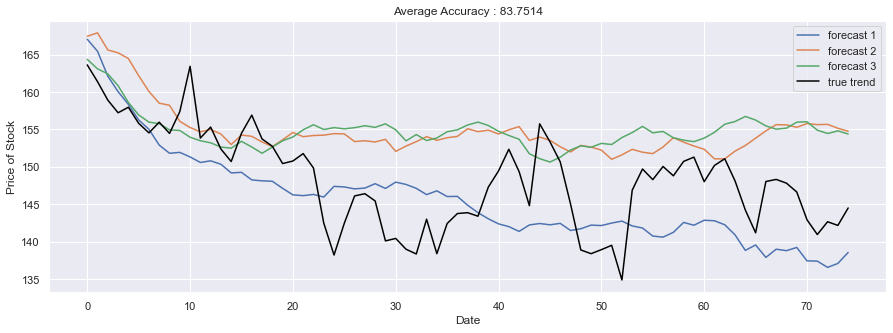

In [10]:
import random
accuracies = [calculate_accuracy(df['Close'].iloc[-test_size:].values, r) for r in results]

random_results = sorted(zip(accuracies, results), reverse=True)[:3]
top_results=[]
for i in random_results:
    top_results.append(i[1])

plt.figure(figsize = (15, 5))
for no, r in enumerate(top_results):
    plt.plot(r, label = 'forecast %d'%(no + 1))
plt.plot(df['Close'].iloc[-test_size:].values, label = 'true trend', c = 'black')
plt.legend()
plt.title('Average Accuracy : %.4f'%(np.mean(accuracies)))
plt.xlabel('Date')
plt.ylabel('Price of Stock')
plt.show()

In [3]:
df = pd.read_csv('dataset//AAPL.csv')
df.head()

NameError: name 'pd' is not defined

In [5]:
df = pd.read_csv('dataset//AAPL.csv')
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2021-12-13,181.119995,182.130005,175.529999,175.740005,174.725922,153237000
1,2021-12-14,175.250000,177.740005,172.210007,174.330002,173.324066,139380400
2,2021-12-15,175.110001,179.500000,172.309998,179.300003,178.265396,131063300
3,2021-12-16,179.279999,181.139999,170.750000,172.259995,171.266006,150185800
4,2021-12-17,169.929993,173.470001,169.690002,171.139999,170.152466,195432700


In [6]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,252.000000,252.000000,252.000000,252.000000,252.000000,2.520000e+02
mean,157.000754,159.148095,154.921786,157.088452,156.580730,8.891628e+07
std,12.980935,12.775973,12.987144,12.870579,12.654395,2.524959e+07
min,130.070007,132.389999,129.039993,130.059998,129.664490,3.519590e+07
25%,145.817505,148.075005,144.239994,146.474998,146.131775,7.152005e+07
50%,156.555000,158.580001,153.934998,156.779999,156.078911,8.447425e+07
75%,168.764996,170.549995,166.642498,168.527503,167.925308,9.821470e+07
max,182.630005,182.940002,179.119995,182.009995,180.959747,1.954327e+08


In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       252 non-null    object 
 1   Open       252 non-null    float64
 2   High       252 non-null    float64
 3   Low        252 non-null    float64
 4   Close      252 non-null    float64
 5   Adj Close  252 non-null    float64
 6   Volume     252 non-null    int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 13.9+ KB
None
